# Fase 4 · LightGBM

¿Mejora el machine learning a los modelos clásicos de la fase 3? Usamos **el mismo backtesting de origen
móvil**, para que la comparación sea justa.

1. Planteamiento: qué predice el modelo y con qué variables
2. Selección de variables y parámetros en un periodo de validación aparte
3. Evaluación final frente a los modelos clásicos
4. Error por año, por horizonte y cara a cara
5. Intervalos de predicción
6. Qué ha aprendido el modelo (SHAP)
7. Previsión de octubre de 2026 a septiembre de 2027
8. Conclusiones

Código: `src/modelo_lgbm.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import modelo_lgbm as ml
from backtest import CALENDARIO, backtest, cargar_dataset, mape_por_horizonte, metricas
from descarga import calendario
from modelos_base import MODELOS

FIG = RAIZ / "outputs" / "figuras"
AZUL, NARANJA, AQUA, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.grid": True,
    "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "lines.linewidth": 2, "legend.frameon": False, "font.size": 10.5,
})
miles = mticker.FuncFormatter(lambda x, _: (f"{x/1e6:g} M" if x >= 1e6 else f"{x/1e3:.0f} k").replace(".", ","))
coma = lambda x, dec=2: f"{x:.{dec}f}".replace(".", ",")

def guardar(nombre):
    plt.savefig(FIG / f"{nombre}.png", bbox_inches="tight")
    plt.show()

def cache(nombre, calcular, recalcular=False):
    ruta = RAIZ / "outputs" / nombre
    if ruta.exists() and not recalcular:
        return pd.read_csv(ruta, parse_dates=["fecha", "origen"])
    df = calcular()
    df.to_csv(ruta, index=False)
    return df

OBJ = "costa_blanca_pernoctaciones_total"
d = cargar_dataset()
RECALCULAR = False      # True para repetir todos los backtests (unos 8 minutos)

## 1. Planteamiento

**Previsión directa a varios horizontes.** Para cada mes origen T (último dato conocido) y cada horizonte
h = 1 … 12, el mes a prever es M = T + h, y su **mes base** es el mismo mes del año anterior, B = M − 12,
que ya es conocido.

**El modelo no predice las pernoctaciones, sino su crecimiento interanual:**

$$z = \log(y_M) - \log(y_B) \qquad\Rightarrow\qquad \hat y_M = y_B \cdot e^{\hat z}$$

La estacionalidad la pone el mes base, y LightGBM se concentra en el crecimiento, que es lo que fallaba
en la fase 3 (todos los modelos se quedaban cortos en los años de aceleración).

Un solo modelo sirve para los 12 horizontes (h es una variable más) y se **vuelve a entrenar en cada
origen** solo con datos hasta T.

| Grupo | Variables | Cuándo se conocen |
|---|---|---|
| Horizonte y mes | `h`, `mes_objetivo` | siempre |
| Calendario | diferencia con el mes base en días de Semana Santa, fines de semana y días del mes | de antemano |
| Momento | crecimiento interanual del último mes y medias de 3, 6 y 12 meses; crecimiento del mes base | hasta T |
| Tipo de cliente | crecimiento de residentes y extranjeros (3 meses) | hasta T |
| Oferta | crecimiento de plazas (3 meses) | hasta T |
| Aeropuerto | crecimiento de pasajeros internacionales y nacionales (3 meses) | **hasta T − 3**: retraso de Eurostat |

Las filas en las que el mes a prever o el mes base son COVID no se usan para entrenar.

In [2]:
tr = ml.entrenamiento(d, OBJ, ml.VARIABLES_TODAS)
print(f"Filas de entrenamiento con todos los datos: {len(tr)} "
      f"({tr.origen.min():%Y-%m} → {tr.origen.max():%Y-%m}, 12 horizontes)")
tr[["origen", "fecha", "h", "z", "ss_dif", "crec_12", "crec_base", "crec_aero_intl_3"]].tail(3).round(3)

Filas de entrenamiento con todos los datos: 3330 (2000-01 → 2026-08, 12 horizontes)


,origen,fecha,h,z,ss_dif,crec_12,crec_base,crec_aero_intl_3
3826,2025-07-01,2026-07-01,12,0.033,0.0,0.023,0.041,0.144
3827,2025-08-01,2026-08-01,12,0.006,0.0,0.026,0.033,0.114
3828,2025-09-01,2026-09-01,12,0.037,0.0,0.022,0.021,0.090


## 2. Selección en un periodo de validación aparte

Si eligiéramos variables y parámetros mirando los mismos periodos con los que luego comparamos
(2015–2019 y 2023–2026), el resultado final saldría **inflado**. Por eso todas las decisiones se toman en
**2010–2014**, y los periodos de evaluación solo se miran una vez, al final.

### 2.1 Qué grupos de variables

In [3]:
CAL = ["h", "mes_objetivo", "ss_dif", "finde_dif", "dias_dif"]
MOM = ["crec_1", "crec_3", "crec_6", "crec_12", "crec_base"]
CLI, OFE, AER = ["crec_ext_3", "crec_esp_3"], ["crec_plazas_3"], ["crec_aero_intl_3", "crec_aero_nac_3"]
CONJUNTOS = {
    "Calendario + momento": CAL + MOM,
    "+ aeropuerto": CAL + MOM + AER,
    "+ tipo de cliente": CAL + MOM + CLI,
    "+ cliente y oferta": CAL + MOM + CLI + OFE,
    "Todas": ml.VARIABLES_TODAS,
}
VAL = dict(eval_desde="2010-01-01", eval_hasta="2014-12-01")
P8 = dict(num_leaves=8)                    # parámetros iniciales

def calc_conjuntos():
    return pd.concat([backtest(d, ml.hacer_lgbm(v, intervalos=False, params=P8), OBJ, nombre=n, **VAL)
                      for n, v in CONJUNTOS.items()])

val_vars = cache("validacion_fase4_variables.csv", calc_conjuntos, RECALCULAR)
metricas(val_vars).loc[list(CONJUNTOS), ["MAPE", "sesgo_pct"]].round(2)

,MAPE,sesgo_pct
modelo,,
Calendario + momento,4.39,-1.62
+ aeropuerto,4.29,-1.53
+ tipo de cliente,4.57,-1.78
+ cliente y oferta,4.61,-1.70
Todas,4.42,-1.83


El aeropuerto mejora la validación; el tipo de cliente y la oferta la empeoran (añaden ruido con tan
pocos datos). Nos quedamos con **calendario + momento + aeropuerto**.

### 2.2 Parámetros

In [4]:
V = CAL + MOM + AER
CONFIGS = {
    "Inicial (8 hojas)": dict(params=dict(num_leaves=8)),
    "4 hojas": dict(params=dict(num_leaves=4)),
    "16 hojas": dict(params=dict(num_leaves=16, min_child_samples=20)),
    "200 árboles": dict(params=dict(num_leaves=8, n_estimators=200)),
    "Pérdida L1": dict(params=dict(num_leaves=8), objetivo_lgb="l1"),
    "4 hojas + L1": dict(params=dict(num_leaves=4), objetivo_lgb="l1"),
    "Peso a lo reciente (vida media 8 años)": dict(params=dict(num_leaves=8), vida_media=8),
}

def calc_configs():
    return pd.concat([backtest(d, ml.hacer_lgbm(V, intervalos=False, **c), OBJ, nombre=n, **VAL)
                      for n, c in CONFIGS.items()])

def calc_clasicos_val():
    nombres = ["Ingenuo estacional", "SARIMAX + Semana Santa", "Combinación ETS + SARIMAX"]
    return pd.concat([backtest(d, MODELOS[n], OBJ, nombre=n, **VAL) for n in nombres])

val_cfg = cache("validacion_fase4_parametros.csv", calc_configs, RECALCULAR)
val_cla = cache("validacion_fase4_clasicos.csv", calc_clasicos_val, RECALCULAR)
pd.concat([metricas(val_cfg), metricas(val_cla)])[["MAPE", "sesgo_pct"]].sort_values("MAPE").round(2)

,MAPE,sesgo_pct
modelo,,
4 hojas,4.17,-1.72
Pérdida L1,4.19,-1.48
200 árboles,4.20,-1.55
4 hojas + L1,4.22,-1.46
Inicial (8 hojas),4.29,-1.53
Peso a lo reciente (vida media 8 años),4.29,-1.50
SARIMAX + Semana Santa,4.34,-0.77
Ingenuo estacional,4.49,-1.82
16 hojas,4.61,-1.41


**Lectura de la validación:**
- Los árboles **más simples** (4 hojas) funcionan mejor: con unos pocos miles de filas muy
  correlacionadas, los árboles complejos memorizan ruido.
- En 2010–2014, LightGBM (4,17 %) supera a todos los clásicos, incluida la combinación ETS + SARIMAX
  (4,89 %), que en este periodo funciona peor que el ingenuo.

### 2.3 ¿Combinar con un modelo clásico?

In [5]:
mejor = val_cfg[val_cfg.modelo == "4 hojas"]
todo = pd.concat([mejor, val_cla])
w = todo.pivot_table(index=["origen", "fecha"], columns="modelo", values="pred")
real = todo.drop_duplicates(["origen", "fecha"]).set_index(["origen", "fecha"]).real
filas_c = {}
for nombre, cols in {"LightGBM + SARIMAX": ["4 hojas", "SARIMAX + Semana Santa"],
                     "LightGBM + combinación ETS/SARIMAX": ["4 hojas", "Combinación ETS + SARIMAX"]}.items():
    p = np.exp(np.log(w[cols]).mean(axis=1))
    e = (p - real) / real * 100
    filas_c[nombre] = {"MAPE": e.abs().mean(), "sesgo_pct": e.mean()}
pd.DataFrame(filas_c).T.round(2)

,MAPE,sesgo_pct
LightGBM + SARIMAX,3.98,-1.26
LightGBM + combinación ETS/SARIMAX,4.27,-1.40


Combinar LightGBM con SARIMAX + Semana Santa baja la validación a **3,98 %**.

**Configuración fijada antes de mirar los periodos de evaluación:**
- **LightGBM:** calendario + momento + aeropuerto, árboles de 4 hojas, 400 árboles, pérdida L2
  (`modelo_lgbm.lgbm`).
- **Modelo final:** media geométrica de LightGBM y SARIMAX + Semana Santa (`modelo_lgbm.lgbm_mas_sarimax`).

## 3. Evaluación final frente a los modelos clásicos

In [6]:
PERIODOS = {"2015–2019": ("2015-01-01", "2019-12-01"), "2023–2026": ("2023-04-01", None)}

def calc_test():
    partes = []
    for per, (a, b) in PERIODOS.items():
        for n, f in {"LightGBM": ml.lgbm, "LightGBM + SARIMAX": ml.lgbm_mas_sarimax}.items():
            partes.append(backtest(d, f, OBJ, eval_desde=a, eval_hasta=b, nombre=n).assign(periodo=per))
    return pd.concat(partes)

f4 = cache("backtest_fase4.csv", calc_test, RECALCULAR)
f3 = pd.read_csv(RAIZ / "outputs" / "backtest_fase3.csv", parse_dates=["fecha", "origen"])
ORDEN = ["Ingenuo estacional", "SARIMAX + Semana Santa", "Combinación ETS + SARIMAX", "LightGBM", "LightGBM + SARIMAX"]
res = pd.concat([f3[f3.modelo.isin(ORDEN)], f4])
tabla = metricas(res, ["periodo", "modelo"])
resumen = tabla[["MAPE", "sesgo_pct"]].unstack(0)
resumen.columns = [f"{m} {p}" for m, p in resumen.columns]
resumen.loc[ORDEN].round(2)

,MAPE 2015–2019,MAPE 2023–2026,sesgo_pct 2015–2019,sesgo_pct 2023–2026
modelo,,,,
Ingenuo estacional,4.74,4.50,-2.04,-3.17
SARIMAX + Semana Santa,4.61,3.61,-3.18,-2.02
Combinación ETS + SARIMAX,4.24,3.48,-2.04,-2.09
LightGBM,4.26,3.83,-1.07,-1.36
LightGBM + SARIMAX,4.21,3.56,-2.14,-1.70


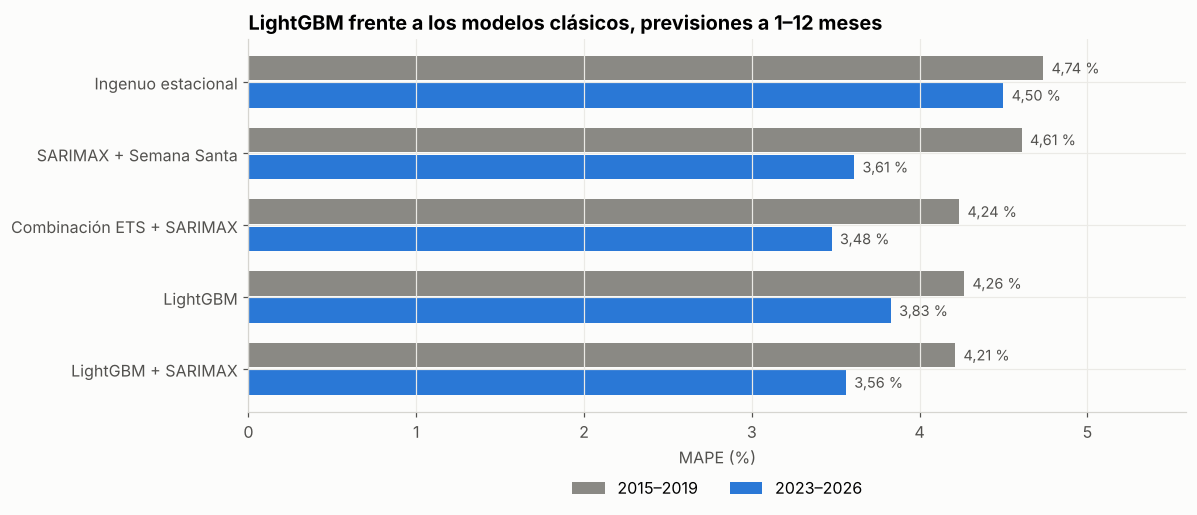

In [7]:
mape = tabla["MAPE"].unstack(0).loc[ORDEN]
fig, ax = plt.subplots(figsize=(11, 4.4))
y_pos = np.arange(len(ORDEN)); alto = 0.38
for i, (per, col) in enumerate(zip(PERIODOS, [GRIS, AZUL])):
    v = mape[per]
    ax.barh(y_pos + (i - 0.5) * alto, v, height=alto - 0.04, color=col, label=per)
    for yy, val in zip(y_pos + (i - 0.5) * alto, v):
        ax.text(val + 0.05, yy, coma(val) + " %", va="center", fontsize=9.5, color="#52514e")
ax.set_yticks(y_pos, ORDEN); ax.invert_yaxis()
ax.set_xlim(0, mape.max().max() * 1.18); ax.set_xlabel("MAPE (%)")
ax.set_title("LightGBM frente a los modelos clásicos, previsiones a 1–12 meses")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
guardar("15_mape_lightgbm")

**Lectura: LightGBM no mejora a los modelos clásicos. Empata.**
- **2015–2019:** LightGBM + SARIMAX es el mejor (4,21 %), pero solo 0,03 puntos por delante de la
  combinación ETS + SARIMAX (4,24 %). LightGBM solo queda en 4,26 %.
- **2023–2026:** la combinación clásica sigue siendo la mejor (3,48 %). LightGBM + SARIMAX queda
  en 3,56 % y LightGBM solo, en 3,83 %.
- **Lo que sí consigue LightGBM: menos sesgo.** Solo se queda corto un 1,1–1,4 % de media, frente al
  2,0–2,1 % de la combinación clásica.

En validación (2010–2014) LightGBM ganaba con claridad, y en los periodos de evaluación no. Eso es justo
lo que la separación entre validación y evaluación sirve para detectar: con solo 25 años de datos
mensuales, la ventaja que parece tener un modelo en un periodo no se mantiene necesariamente en otro.

## 4. Error por año, por horizonte y cara a cara

In [8]:
anual = (res.assign(año=res.fecha.dt.year, ape=res.error_pct.abs())
            .pivot_table(index=["periodo", "año"], columns="modelo", values="ape")[ORDEN[1:]])
anual.round(2)

modelo          SARIMAX + Semana Santa  Combinación ETS + SARIMAX  LightGBM  \
periodo   año                                                                 
2015–2019 2015                    5.68                       4.87      3.51   
          2016                    8.04                       7.18      7.34   
          2017                    3.88                       3.28      2.87   
          2018                    2.53                       2.66      2.80   
          2019                    3.40                       3.48      4.47   
2023–2026 2023                    4.03                       3.97      5.14   
          2024                    5.20                       5.13      5.61   
          2025                    2.58                       2.41      2.73   
          2026                    2.73                       2.53      2.42   

modelo          LightGBM + SARIMAX  
periodo   año                       
2015–2019 2015                4.42  
          2016                7.50  
          2017                3.02  
          2018                2.44  
          2019                3.77  
2023–2026 2023                4.55  
          2024                5.33  
          2025                2.31  
          2026                2.50

**Lectura:** ningún modelo resuelve los dos años de aceleración, **2016** (error del 7–8 %) y **2024**
(5–6 %). Con la información disponible en cada momento, esos saltos no se podían anticipar. LightGBM es
mejor en 2015 y 2017, y peor en 2019 y 2023.

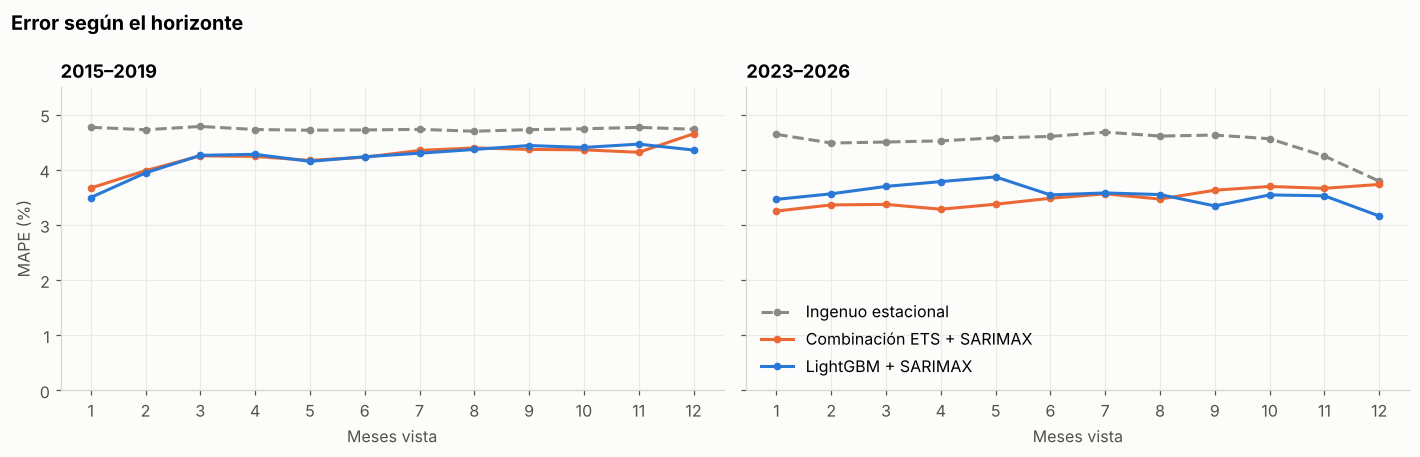

2015–2019 · a 1 mes: {'Combinación ETS + SARIMAX': '3,67', 'LightGBM + SARIMAX': '3,50'} · a 12 meses: {'Combinación ETS + SARIMAX': '4,65', 'LightGBM + SARIMAX': '4,36'}
2023–2026 · a 1 mes: {'Combinación ETS + SARIMAX': '3,25', 'LightGBM + SARIMAX': '3,46'} · a 12 meses: {'Combinación ETS + SARIMAX': '3,73', 'LightGBM + SARIMAX': '3,16'}


In [9]:
hz = mape_por_horizonte(res[res.periodo == "2023–2026"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, per in zip(axes, PERIODOS):
    hz = mape_por_horizonte(res[res.periodo == per])
    for m, col, ls in [("Ingenuo estacional", GRIS, "--"), ("Combinación ETS + SARIMAX", NARANJA, "-"),
                       ("LightGBM + SARIMAX", AZUL, "-")]:
        ax.plot(hz.index, hz[m], color=col, ls=ls, marker="o", ms=4, label=m)
    ax.set_xticks(range(1, 13)); ax.set_xlabel("Meses vista"); ax.set_title(per, fontsize=12)
axes[0].set_ylabel("MAPE (%)"); axes[0].set_ylim(0, 5.5)
axes[1].legend(loc="lower left")
fig.suptitle("Error según el horizonte", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
guardar("16_horizonte_lightgbm")

for per in PERIODOS:
    hz = mape_por_horizonte(res[res.periodo == per])
    print(per, "· a 1 mes:", {m: coma(hz.at[1, m]) for m in ["Combinación ETS + SARIMAX", "LightGBM + SARIMAX"]},
          "· a 12 meses:", {m: coma(hz.at[12, m]) for m in ["Combinación ETS + SARIMAX", "LightGBM + SARIMAX"]})

In [10]:
w = res.assign(ape=res.error_pct.abs()).pivot_table(index=["periodo", "origen"], columns="modelo", values="ape")
gana = (w["LightGBM + SARIMAX"] < w["Combinación ETS + SARIMAX"]).groupby("periodo").mean() * 100
print("Orígenes en los que LightGBM + SARIMAX tiene menos error que la combinación clásica:")
print(gana.round(0).astype(int).astype(str).add(" %").to_string())

Orígenes en los que LightGBM + SARIMAX tiene menos error que la combinación clásica:
periodo
2015–2019    48 %
2023–2026    52 %


**Lectura:**
- **A largo plazo, LightGBM + SARIMAX es mejor en los dos periodos.** A 12 meses vista tiene un 4,36 %
  de error frente al 4,65 % en 2015–2019, y un 3,16 % frente al 3,73 % en 2023–2026. Tiene lógica: a
  largo plazo pesa más acertar el crecimiento, que es lo que corrige LightGBM.
- **A corto plazo depende del periodo.** A 1 mes vista, LightGBM + SARIMAX es mejor en 2015–2019 (3,50 %
  frente a 3,67 %) y peor en 2023–2026 (3,46 % frente a 3,25 %).
- **Cara a cara**, LightGBM + SARIMAX gana en la mitad de los meses origen (48 % y 52 %): un empate.

## 5. Intervalos de predicción

In [11]:
cob = tabla["cobertura"].unstack(0).loc[["SARIMAX + Semana Santa", "Combinación ETS + SARIMAX", "LightGBM", "LightGBM + SARIMAX"]]
cob.round(1)

periodo,2015–2019,2023–2026
modelo,,
SARIMAX + Semana Santa,79.1,91.6
Combinación ETS + SARIMAX,81.0,90.4
LightGBM,76.0,73.1
LightGBM + SARIMAX,76.0,75.8


Intervalos del 80 %. Los de LightGBM salen de dos modelos de **regresión cuantil** (cuantiles 10 y 90)
entrenados igual que el principal.

**Lectura:** los intervalos de LightGBM se quedan algo estrechos (cobertura del 73–76 % en lugar del 80 %).
Los de SARIMAX eran demasiado anchos después del COVID (90–92 %). Ninguno es perfecto, pero los de
LightGBM son más **útiles** después del COVID: más estrechos y con una cobertura más cercana a la prometida.

## 6. Qué ha aprendido el modelo (SHAP)

Los **valores SHAP** reparten cada predicción entre las variables: cuánto suma o resta cada una al
crecimiento previsto. LightGBM los calcula directamente (`pred_contrib=True`). Usamos el modelo
entrenado con todos los datos.

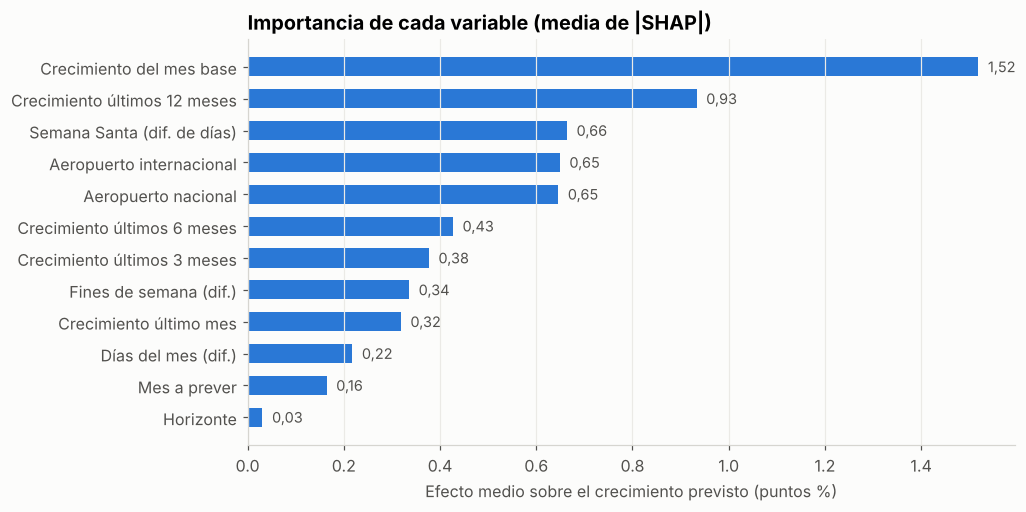

In [12]:
tr = ml.entrenamiento(d, OBJ)
m = ml.ajustar(tr)
X = tr[ml.VARIABLES]
contrib = m.predict(X, pred_contrib=True)
shap = pd.DataFrame(contrib[:, :-1], columns=ml.VARIABLES, index=X.index) * 100   # puntos de crecimiento (%)
imp = shap.abs().mean().sort_values()

NOMBRES = {
    "crec_base": "Crecimiento del mes base", "crec_12": "Crecimiento últimos 12 meses",
    "ss_dif": "Semana Santa (dif. de días)", "crec_aero_intl_3": "Aeropuerto internacional",
    "crec_aero_nac_3": "Aeropuerto nacional", "crec_6": "Crecimiento últimos 6 meses",
    "crec_3": "Crecimiento últimos 3 meses", "finde_dif": "Fines de semana (dif.)",
    "crec_1": "Crecimiento último mes", "dias_dif": "Días del mes (dif.)",
    "mes_objetivo": "Mes a prever", "h": "Horizonte",
}
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh([NOMBRES[v] for v in imp.index], imp.values, color=AZUL, height=0.6)
for i, val in enumerate(imp.values):
    ax.text(val + 0.02, i, coma(val), va="center", fontsize=9.5, color="#52514e")
ax.set_xlabel("Efecto medio sobre el crecimiento previsto (puntos %)")
ax.set_title("Importancia de cada variable (media de |SHAP|)")
ax.grid(axis="y", visible=False)
guardar("17_shap_importancia")

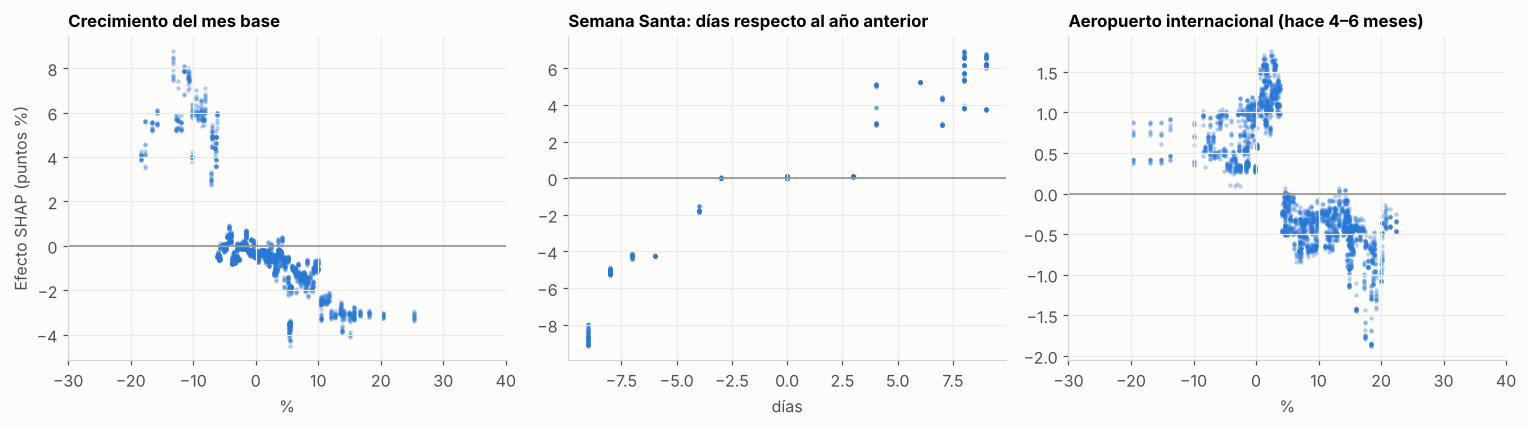

Correlación entre el crecimiento del aeropuerto y su efecto SHAP: -0,60


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, var, titulo in zip(axes, ["crec_base", "ss_dif", "crec_aero_intl_3"],
                           ["Crecimiento del mes base", "Semana Santa: días respecto al año anterior", "Aeropuerto internacional (hace 4–6 meses)"]):
    x = X[var] * (100 if var != "ss_dif" else 1)
    ax.scatter(x, shap[var], s=8, alpha=0.35, color=AZUL, lw=0)
    ax.axhline(0, color=GRIS, lw=1)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("%" if var != "ss_dif" else "días")
axes[0].set_xlim(-30, 40); axes[2].set_xlim(-30, 40)
axes[0].set_ylabel("Efecto SHAP (puntos %)")
plt.tight_layout()
guardar("18_shap_dependencia")

print("Correlación entre el crecimiento del aeropuerto y su efecto SHAP:",
      coma(np.corrcoef(X.crec_aero_intl_3.fillna(0), shap.crec_aero_intl_3)[0, 1]))

**Lectura:**
1. **Crecimiento del mes base: efecto rebote.** Es la variable más importante, y actúa al revés de lo
   intuitivo. Si un mes creció mucho respecto a su año anterior, el modelo espera que el año siguiente
   crezca menos, y si cayó, que se recupere. Los meses atípicos tienden a volver a lo normal.
2. **Crecimiento de los últimos 12 meses: inercia.** Si el último año ha ido bien, el modelo prevé más
   crecimiento.
3. **Semana Santa.** Cuando el mes a prever gana 6–9 días de Semana Santa respecto al año anterior, el
   crecimiento previsto sube entre 4 y 6 puntos; cuando los pierde, baja entre 4 y 9. Es el efecto que
   vimos en el EDA, y aquí sale de los datos sin decírselo al modelo.
4. **Aeropuerto: atención.** Entra con **signo contrario al lógico** (correlación de −0,6 con su efecto):
   más pasajeros hace 4–6 meses resta crecimiento hotelero. Lo más probable es que sea una relación
   espuria. En el EDA vimos que el aeropuerto crece mucho más que los hoteles (cada pasajero deja cada
   vez menos pernoctaciones hoteleras), así que un aeropuerto en auge no anticipa más hoteles. La
   variable mejoró la validación, pero **no es una relación en la que conviene confiar**. Una versión
   futura debería quitarla o sustituirla por datos de AENA, más actuales.

## 7. Previsión de octubre de 2026 a septiembre de 2027

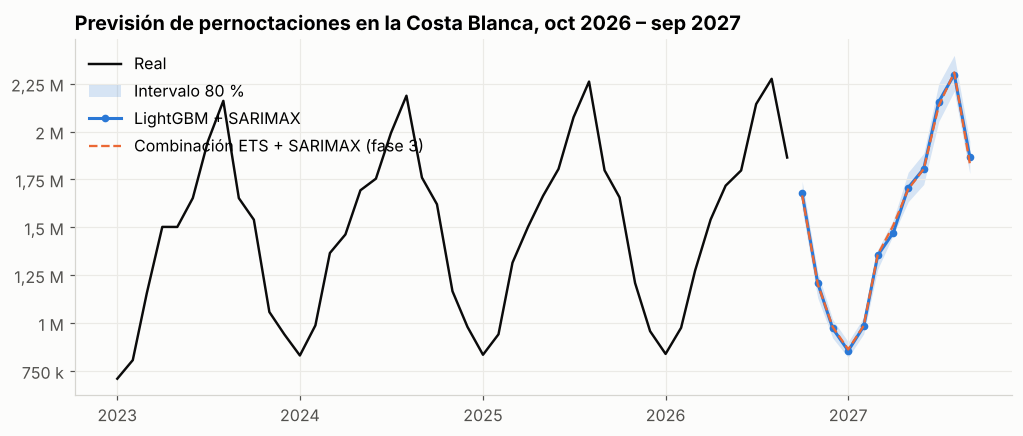

Total previsto: 18,36 M (fase 3: 18,35 M) · 12 meses anteriores: 18,25 M


,pred,inf,sup,pred_fase3,año_anterior,variación %
oct 2026,1677,1594,1740,1666,1656,1.3
nov 2026,1209,1132,1266,1204,1209,0.0
dic 2026,972,922,1019,980,958,1.5
ene 2027,855,820,902,862,839,2.0
feb 2027,983,943,1030,986,975,0.7
mar 2027,1354,1281,1383,1358,1274,6.2
abr 2027,1472,1459,1538,1509,1540,-4.5
may 2027,1707,1634,1787,1699,1717,-0.6
jun 2027,1806,1724,1886,1804,1797,0.5
jul 2027,2156,2052,2250,2135,2143,0.6


In [14]:
T = d[OBJ].last_valid_index()
futuro = calendario((T + pd.DateOffset(months=1)).strftime("%Y-%m-%d"),
                    (T + pd.DateOffset(months=12)).strftime("%Y-%m-%d")).set_index("fecha")
futuro["covid"] = 0
fut = futuro[[c for c in CALENDARIO if c in futuro]]
prev = ml.lgbm_mas_sarimax(d, fut, OBJ)
prev_f3 = pd.read_csv(RAIZ / "outputs" / "prevision_2026_2027.csv", parse_dates=["fecha"]).set_index("fecha")
prev["año_anterior"] = [d.at[f - pd.DateOffset(months=12), OBJ] for f in prev.index]
prev["variacion_pct"] = (prev.pred / prev.año_anterior - 1) * 100
prev["pred_fase3"] = prev_f3["pred"]
prev.to_csv(RAIZ / "outputs" / "prevision_2026_2027_fase4.csv")

hist = d.loc["2023-01":, OBJ]
fig, ax = plt.subplots()
ax.plot(hist.index, hist, color=TINTA, lw=1.6, label="Real")
ax.fill_between(prev.index, prev["inf"], prev["sup"], color=AZUL, alpha=0.18, lw=0, label="Intervalo 80 %")
ax.plot(prev.index, prev.pred, color=AZUL, marker="o", ms=4, label="LightGBM + SARIMAX")
ax.plot(prev.index, prev.pred_fase3, color=NARANJA, ls="--", lw=1.5, label="Combinación ETS + SARIMAX (fase 3)")
ax.yaxis.set_major_formatter(miles)
ax.set_title("Previsión de pernoctaciones en la Costa Blanca, oct 2026 – sep 2027")
ax.legend(loc="upper left")
guardar("19_prevision_fase4")

MESES = "ene feb mar abr may jun jul ago sep oct nov dic".split()
t = (prev[["pred", "inf", "sup", "pred_fase3", "año_anterior"]] / 1e3).round(0).astype(int)
t["variación %"] = prev.variacion_pct.round(1)
t.index = [f"{MESES[f.month - 1]} {f.year}" for f in t.index]
print(f"Total previsto: {coma(prev.pred.sum()/1e6)} M (fase 3: {coma(prev.pred_fase3.sum()/1e6)} M) · "
      f"12 meses anteriores: {coma(d[OBJ].iloc[-12:].sum()/1e6)} M")
t

**Lectura:** las dos previsiones son muy parecidas mes a mes; la tabla da el total y la variación de
cada mes. Que dos enfoques tan distintos (series temporales clásicas y LightGBM sobre el crecimiento)
lleguen a cifras casi iguales da confianza en la previsión.

## 8. Conclusiones

| | Resultado |
|---|---|
| **¿Gana el machine learning?** | No. LightGBM + SARIMAX empata con la combinación clásica: 4,21 % frente a 4,24 % antes del COVID, 3,56 % frente a 3,48 % después |
| **Lo que aporta** | LightGBM solo reduce el sesgo a la mitad; la combinación final, menos error a 12 meses vista en los dos periodos (4,36 % frente a 4,65 % y 3,16 % frente a 3,73 %) e intervalos más útiles después del COVID |
| **Lo que no resuelve** | Las aceleraciones de 2016 y 2024: ningún modelo las anticipa |
| **Qué ha aprendido** | Rebote de los meses atípicos, inercia de los últimos 12 meses y Semana Santa |
| **Advertencia** | El aeropuerto entra con un signo poco creíble; conviene quitarlo o cambiar a datos de AENA |

**Por qué el resultado es razonable:** con unos 25 años de datos mensuales y una serie tan estacional,
los modelos clásicos ya capturan casi toda la información. Es lo que suelen encontrar las competiciones
de previsión: el machine learning brilla con muchas series o muchas variables explicativas, no con una
sola serie mensual. El valor de esta fase está en haberlo comprobado con una evaluación justa: mismo
backtesting, selección en un periodo de validación aparte y evaluación final una sola vez.

**Modelo para la app (fase 5):** **LightGBM + SARIMAX**, el elegido en validación. Empata en precisión,
acierta más a 12 meses vista, tiene menos sesgo y mejores intervalos después del COVID, y permite
explicar cada previsión con SHAP.